<a href="https://colab.research.google.com/github/sdkfjuecsec/ProteinMPNN/blob/main/colab_notebooks/quickdemo_wAF2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ProteinMPNN w/AF2
This notebook is intended as a quick demo, more features to come!

Examples:
1.   pdb: `6MRR`, homomer: `False`, designed_chain: `A`
2.   pdb: `1X2I`, homomer: `True`, designed_chain: `A,B`
     (for correct symmetric tying lenghts of homomer chains should be the same)

In [1]:
#@title Setup ProteinMPNN
# Silence FutureWarning noise coming from third-party libraries
import warnings

# Apply the filter to every warning category
warnings.simplefilter(action='ignore', category=FutureWarning)

# Standard-library modules: filesystem paths and regex helpers
import os
import re
import sys

# Typing helpers used by the annotations in this notebook
from typing import Any

# NumPy for array handling
import numpy as np

# Colab helper used by get_pdb() below to prompt for an uploaded PDB file
from google.colab import files

# Clone this study fork once; later runs reuse the existing folder
if not os.path.isdir("ProteinMPNN"):
  os.system("git clone -q https://github.com/sdkfjuecsec/ProteinMPNN.git")

# Make the cloned package importable (the Colab working directory is /content)
if "ProteinMPNN" not in sys.path:
  sys.path.append('/content/ProteinMPNN')

# PyTorch and the deep-copy helper used below
import copy

import torch

# Single source of truth for the amino-acid alphabet; its length is the model's num_letters
from constants import PROTEIN_ALPHABET

# Project helpers: scoring, sequence decoding, featurization, PDB parsing, and the model class
from protein_mpnn_utils import (
  ProteinMPNN,
  StructureDatasetPDB,
  TiedFeatures,
  _S_to_seq,
  _scores,
  parse_PDB,
  tied_featurize,
)

# Use CUDA when a GPU is available, otherwise fall back to CPU
device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#v_48_010=version with 48 edges 0.10A noise
# Checkpoint to load: v_48_002 / v_48_010 / v_48_020 / v_48_030 (larger number = more training noise)
model_name: str = "v_48_020" #@param ["v_48_002", "v_48_010", "v_48_020", "v_48_030"]


# Standard deviation of Gaussian noise added to backbone atoms (0.0 = no noise)
backbone_noise: float = 0.00               # Standard deviation of Gaussian noise to add to backbone atoms

# Folder holding the full-backbone model weights
path_to_model_weights: str = '/content/ProteinMPNN/vanilla_model_weights'
# Architecture parameters that must agree with the checkpoint
hidden_dim: int = 128
# Number of encoder and decoder layers
num_layers: int = 3
# Full checkpoint path, e.g. .../vanilla_model_weights/v_48_020.pt;
# os.path.join handles a missing or trailing '/' in the folder
checkpoint_path: str = os.path.join(path_to_model_weights, f'{model_name}.pt')

# Load the checkpoint onto the selected device; keys: num_edges, noise_level, model_state_dict
checkpoint: dict[str, Any] = torch.load(checkpoint_path, map_location=device)
# Number of k-nearest-neighbour edges the checkpoint was trained with
print('Number of edges:', checkpoint['num_edges'])
# Backbone noise level (Angstroms) used during training
noise_level_print: float = checkpoint['noise_level']
# Print the parsed training noise level
print(f'Training noise level: {noise_level_print}A')
# Build the model with the same architecture as the checkpoint
model: ProteinMPNN = ProteinMPNN(
    num_letters=len(PROTEIN_ALPHABET),
    node_features=hidden_dim,
    edge_features=hidden_dim,
    hidden_dim=hidden_dim,
    num_encoder_layers=num_layers,
    num_decoder_layers=num_layers,
    augment_eps=backbone_noise,
    k_neighbors=checkpoint['num_edges'],
)
# Move the model parameters to the selected device
model.to(device)
# Copy the trained weights into the model
model.load_state_dict(checkpoint['model_state_dict'])
# Evaluation mode disables dropout and other training-only behaviour
model.eval()
# Report that setup finished
print("Model loaded")

Number of edges: 48
Training noise level: 0.2A
Model loaded


In [2]:
def make_tied_positions_for_homomers(pdb_dict_list: list[dict[str, Any]]) -> dict[str, list[dict[str, list[int]]]]:
    '''Build tied-position groups for a homo-oligomer.

    Equivalent residues of the homo chains are decoded together instead of
    independently, so every copy of the chain receives the same amino acid.

    Args:
        pdb_dict_list: parsed PDB entries from parse_PDB(), one dict per structure.
            Only the 'name' and per-chain 'seq_chain_<chain ID>' keys are read.
            E.g. for 1X2I with chains A and B of length 68:
            [
                {
                    'name': '1X2I',              # PDB id, scalar str
                    'seq_chain_A': 'MSTN...',    # [68] one-letter sequence
                    'seq_chain_B': 'MSTN...',    # [68] one-letter sequence
                },
            ]

    Returns:
        dict[str, list[dict[str, list[int]]]]: PDB name -> one tied group per
        residue position. Each group maps a chain ID to a 1-based chain-local
        position; this is the unweighted form accepted by tied_featurize(). E.g.
        {
            '1X2I': [
                {'A': [1], 'B': [1]},   # position 1 of A and B shares one draw
                {'A': [2], 'B': [2]},   # position 2
                ...                     # 68 groups for a 68-residue chain
            ],
        }
    '''
    # Output mapping: PDB name -> tied groups
    tied_positions_per_structure: dict[str, list[dict[str, list[int]]]] = {}
    # Every parsed structure is handled independently
    for pdb_dict in pdb_dict_list:
        # Chain IDs found in the parsed entry, e.g. ['A', 'B', 'C']; shape = [num_chains]
        # Caution: every chain ID listed here is assumed to be a homomer copy of the
        # same chain, so this function must not be called on heteromers
        all_chain_ids: list[str] = sorted(
            key[len('seq_chain_'):] for key in pdb_dict if key.startswith('seq_chain_')
        )
        # One tied group per residue position, in 1-based numbering; shape = [chain_length]
        tied_positions_list: list[dict[str, list[int]]] = []
        # All homo chains share this length, read from the first chain
        chain_length: int = len(pdb_dict[f"seq_chain_{all_chain_ids[0]}"])
        # i is the 1-based residue index shared by all equivalent chains
        for i in range(1,chain_length+1):
            # One group mapping chain ID -> [residue index]; shape = [num_chains]
            tied_position_group: dict[str, list[int]] = {}
            # Register the same 1-based residue index for every homo chain
            for chain_id in all_chain_ids:
                tied_position_group[chain_id] = [i] #needs to be a list
            # Store this tied group
            tied_positions_list.append(tied_position_group)
        # Key the tied groups by PDB name
        tied_positions_per_structure[pdb_dict['name']] = tied_positions_list
    # Return PDB name -> tied groups
    return tied_positions_per_structure

#########################
# Return a local PDB path: prompt for an upload when no code is given,
# otherwise download the structure from RCSB
def get_pdb(pdb_code: str | None = "") -> str:
  # Empty input means the user wants to upload a file interactively
  if pdb_code is None or pdb_code == "":
    # Colab upload widget returned as filename -> raw bytes; shape = [num_uploaded_files]
    upload_dict: dict[str, bytes] = files.upload()
    # Only the first uploaded file is used
    pdb_string: bytes = upload_dict[list(upload_dict.keys())[0]]
    # Persist the uploaded bytes so parse_PDB can read them from disk
    with open("tmp.pdb","wb") as out:
      out.write(pdb_string)
    # Hand the written path back to the caller
    return "tmp.pdb"
  else:
    # Download from RCSB; -nc keeps an existing local copy untouched
    os.system(f"wget -qnc https://files.rcsb.org/view/{pdb_code}.pdb")
    # Return the downloaded file path
    return f"{pdb_code}.pdb"

In [3]:
#@title #Run ProteinMPNN

#@markdown #### Input Options
# PDB code to design; leave blank to get an upload prompt
pdb: str = '1X2I' #@param {type:"string"}
# Strip stray spaces from the entered code
pdb = pdb.replace(" ","")
# Local path to the PDB file (uploaded copy or RCSB download)
pdb_path: str = get_pdb(pdb)
#@markdown - pdb code (leave blank to get an upload prompt)

# Whether all chains share the same sequence (enables tied sampling)
homomer: bool = True #@param {type:"boolean"}
# Comma-separated chain IDs to redesign, e.g. "A,B"
designed_chain: str = "A,B" #@param {type:"string"}
# Comma-separated chain IDs to keep fixed, e.g. "C"
fixed_chain: str = "" #@param {type:"string"}

# Chain IDs may be comma/space separated; dict.fromkeys() drops duplicates while
# keeping the first-seen order, and empty input gives an empty list
designed_chain_id_list: list[str] = list(dict.fromkeys(re.sub("[^A-Za-z]+", " ", designed_chain).split()))
fixed_chain_id_list: list[str] = list(dict.fromkeys(re.sub("[^A-Za-z]+", " ", fixed_chain).split()))

# A chain cannot be designed and fixed at the same time
overlapping_chains: set[str] = set(designed_chain_id_list) & set(fixed_chain_id_list)
if overlapping_chains:
  raise ValueError(f'Chains listed as both designed and fixed: {sorted(overlapping_chains)}')

# Chains consumed by parse_PDB: designed + fixed; empty means "probe every chain"
all_chain_ids: list[str] = designed_chain_id_list + fixed_chain_id_list

#@markdown - specified which chain(s) to design and which chain(s) to keep fixed.
#@markdown   Use comma:`A,B` to specifiy more than one chain

#chain = "A" #@param {type:"string"}
#pdb_path_chains = chain
##@markdown - Define which chain to redesign

#@markdown #### Design Options
# Number of sequences to sample per target
num_seqs: int = 8 #@param ["1", "2", "4", "8", "16", "32", "64"] {type:"raw"}
# Alias used by the sampling loop below
num_seq_per_target: int = num_seqs

#@markdown - Sampling temperature for amino acids, T=0.0 means taking argmax, T>>1.0 means sample randomly.
# Space-separated temperatures; one sampling pass per value
sampling_temp: str = "0.1" #@param ["0.0001", "0.1", "0.15", "0.2", "0.25", "0.3", "0.5"]

# Batch size; can set higher for titan, quadro GPUs, reduce this if running out of GPU memory
batch_size: int = 1
# Max total residue count accepted by the dataset wrapper
max_length: int = 20000

# Amino acids to omit from the generated sequence, e.g. 'AC' would omit alanine and cysteine;
# 'X' is the unknown-residue placeholder and the 21st symbol of PROTEIN_ALPHABET, so omitting it
# restricts sampling to the 20 standard amino acids
omit_AAs: str = 'X'

# A value between [0.0, 1.0], 0.0 means do not use pssm, 1.0 ignore MPNN predictions
pssm_multi: float = 0.0
# A value between -inf + inf to restrict per-position amino acids
pssm_threshold: float = 0.0
# 0 for False, 1 for True; use PSSM log-odds above the threshold
pssm_log_odds_flag: int = 0
# 0 for False, 1 for True; apply the PSSM bias
pssm_bias_flag: int = 0


##############################################################

# Number of full batches to sample (integer division)
NUM_BATCHES: int = num_seq_per_target//batch_size
# Number of structure copies evaluated per batch (= batch_size)
BATCH_COPIES: int = batch_size
# Requested sampling temperatures; shape = [num_temperatures]
temperatures: list[float] = [float(item) for item in sampling_temp.split()]
# Amino acids to omit, kept as a string of one-letter codes
omit_AAs_list: str = omit_AAs
# Amino-acid alphabet used by the model; 21 symbols including X.
alphabet: str = PROTEIN_ALPHABET

# 0/1 mask of omitted amino acids, aligned with alphabet; shape = [21], dtype = float32,
# where 1.0 marks an omitted type; kept under a mask name while the model keyword stays omit_AAs_np
omit_AAs_np: np.ndarray = np.array([AA in omit_AAs_list for AA in alphabet]).astype(np.float32)

# Optional dictionaries consumed by tied_featurize; None means "not used"
# PDB name -> (designed chain IDs, fixed chain IDs); the official keyword is chain_id_dict, e.g.
#   {
#       '1abc': (['A', 'B'], []),        # redesign chains A and B, keep nothing fixed
#       '2def': (['A'], ['C']),          # redesign chain A only, keep chain C fixed
#   }
chain_id_dict: dict[str, tuple[list[str], list[str]]] | None = None
# PDB name -> {chain ID: fixed residue indices}
fixed_positions_dict: dict[str, dict[str, list[int]]] | None = None
# PDB name -> {chain ID: PSSM data}; Each chain dict holds
# 'pssm_coef' [chain_length], 'pssm_bias' [chain_length, 21] and
# 'pssm_log_odds' [chain_length, 21], e.g.
#   {
#       '1abc': {
#           'A': {
#               'pssm_coef': [0.1, 0.2, ...],                  # [chain_length]
#               'pssm_bias': [[0.0, ...], ...],                # [chain_length, 21]
#               'pssm_log_odds': [[10000.0, ...], ...],        # [chain_length, 21]
#           },
#       },
#   }
pssm_dict: dict[str, dict[str, dict[str, Any]]] | None = None
# PDB name -> {chain ID: list of omitted-amino-acid rules}; each rule is
# [[1-based positions], [omitted amino acids]], e.g.
#   {
#       '1abc': {
#           'A': [
#               [[1, 3, 5], ['A', 'W']],   # forbid A and W at positions 1, 3, 5
#               [[10], ['C']],             # forbid C at position 10
#           ],
#       },
#   }
omit_AA_dict: dict[str, dict[str, list[list[list[int] | list[str]]]]] | None = None
# PDB name -> list of tied groups; each group maps a chain ID to 1-based
# chain-local positions that must receive the same sampled amino acid, e.g.
#   {
#       '1abc': [
#           {'A': [1, 2, 3], 'B': [1, 2, 3]},           # tie A1/A2/A3 with B1/B2/B3
#           {'A': [[5, 6], [1.0, 0.5]],                 # weighted form: positions 5, 6
#            'B': [[5, 6], [1.0, 0.5]]},                # with weights 1.0 and 0.5
#       ],
#   }
tied_positions_dict: dict[str, list[dict[str, list[int] | list[list[int | float]]]]] | None = None
# PDB name -> {chain ID: per-residue bias array}; each array has
# shape = [chain_length, 21] and is aligned with alphabet, e.g.
#   {
#       '1abc': {
#           'A': np.zeros((10, 21)),   # [10, 21]
#           'B': np.zeros((10, 21)),   # [10, 21]
#       },
#   }
bias_by_res_dict: dict[str, dict[str, np.ndarray]] | None = None
# Zero per-amino-acid bias, aligned with alphabet; shape = [21], dtype = float64
bias_AAs_np: np.ndarray = np.zeros(len(alphabet))


###############################################################
# Parse the PDB into the dictionary format expected by tied_featurize; shape = [num_structures]
# Each entry is a plain dict; for 6EHB parsed with chains A and C it looks like
# (sequences and coordinates truncated):
#   {
#       'name': '6EHB',                          # 4-character PDB id, scalar str
#       'num_of_chains': 2,                      # scalar int
#       'seq': 'DGINQSGD...',                    # sequence of all chains, len 640
#       'seq_chain_A': 'DGINQSGD...',            # per-chain sequence, len 320
#       'seq_chain_C': 'DGINQSGD...',            # per-chain sequence, len 320
#       'coords_chain_A': {
#           'N_chain_A': [[x, y, z], ...],       # [320, 3]
#           'CA_chain_A': [[x, y, z], ...],      # [320, 3]
#           'C_chain_A': [[x, y, z], ...],       # [320, 3]
#           'O_chain_A': [[x, y, z], ...],       # [320, 3]
#       },
#       'coords_chain_C': {...},                 # same layout as coords_chain_A
#   }
# Element order in all_chain_ids does not matter: it only affects the concatenated seq field
# and dict key insertion order, while tied_featurize re-sorts chains before building tensors.
pdb_dict_list: list[dict[str, Any]] = parse_PDB(pdb_path, input_chain_list=all_chain_ids)

# No chain selection given: treat every chain found in the file as designed
if not all_chain_ids:
  designed_chain_id_list = [key[len('seq_chain_'):] for key in pdb_dict_list[0] if key.startswith('seq_chain_')]
  fixed_chain_id_list = []
  all_chain_ids = designed_chain_id_list

# Thin dataset wrapper; iterating yields one parsed protein dict per structure
valid_pdb_dataset: StructureDatasetPDB = StructureDatasetPDB(pdb_dict_list, truncate=None, max_length=max_length)

# Mapping from PDB name to (designed chain IDs, fixed chain IDs), e.g.
#   {
#       '6MRR': (['A'], []),       # heteromer: redesign chain A, keep nothing fixed
#       '1X2I': (['A', 'B'], []),  # homomer: redesign both chains
#   }
chain_id_dict: dict[str, tuple[list[str], list[str]]] = {}
# Store the designed/fixed split for this structure
chain_id_dict[pdb_dict_list[0]['name']]= (designed_chain_id_list, fixed_chain_id_list)

# Inspect the resulting split
print(chain_id_dict)
# Report the residue count of every chain involved
for chain_id in all_chain_ids:
  # Current chain length
  l: int = len(pdb_dict_list[0][f"seq_chain_{chain_id}"])
  # Print the chain length
  print(f"Length of chain {chain_id} is {l}")

# Homomers tie equivalent positions so they are decoded together; tied_positions_dict maps
# PDB name -> a list of tied groups, e.g. for homomer chains A and B of length 68:
#   {
#       '1X2I': [
#           {'A': [1], 'B': [1]},   # 1-based position per chain, decoded as one draw
#           {'A': [2], 'B': [2]},
#           ...                     # 68 groups in total
#       ]
#   }
if homomer:
  tied_positions_dict = make_tied_positions_for_homomers(pdb_dict_list)
  print("tied_positions_dict:\n", tied_positions_dict)
else:
  # No tying for heteromers
  tied_positions_dict = None

parse_PDB: parsed 1 structure(s) from 1X2I.pdb
discarded: {'bad_chars': 0, 'too_long': 0}
{'1X2I': (['A', 'B'], [])}
Length of chain A is 68
Length of chain B is 68
tied_positions_dict:
 {'1X2I': [{'A': [1], 'B': [1]}, {'A': [2], 'B': [2]}, {'A': [3], 'B': [3]}, {'A': [4], 'B': [4]}, {'A': [5], 'B': [5]}, {'A': [6], 'B': [6]}, {'A': [7], 'B': [7]}, {'A': [8], 'B': [8]}, {'A': [9], 'B': [9]}, {'A': [10], 'B': [10]}, {'A': [11], 'B': [11]}, {'A': [12], 'B': [12]}, {'A': [13], 'B': [13]}, {'A': [14], 'B': [14]}, {'A': [15], 'B': [15]}, {'A': [16], 'B': [16]}, {'A': [17], 'B': [17]}, {'A': [18], 'B': [18]}, {'A': [19], 'B': [19]}, {'A': [20], 'B': [20]}, {'A': [21], 'B': [21]}, {'A': [22], 'B': [22]}, {'A': [23], 'B': [23]}, {'A': [24], 'B': [24]}, {'A': [25], 'B': [25]}, {'A': [26], 'B': [26]}, {'A': [27], 'B': [27]}, {'A': [28], 'B': [28]}, {'A': [29], 'B': [29]}, {'A': [30], 'B': [30]}, {'A': [31], 'B': [31]}, {'A': [32], 'B': [32]}, {'A': [33], 'B': [33]}, {'A': [34], 'B': [34]}, {'A':

In [4]:
#################################################################
# Designed sequences collected for the AlphaFold step; shape = [num_samples]
sampled_sequences: list[str] = []
# Inference only: gradients are not needed
with torch.no_grad():
  # Announce the sampling stage
  print('Generating sequences...')
  # One parsed protein entry; the dataset holds a single structure here
  for pdb_dict in valid_pdb_dataset:
    # Deep copies so one batch holds B identical structures; shape = [B]
    batch_clones: list[dict[str, Any]] = [copy.deepcopy(pdb_dict) for _ in range(BATCH_COPIES)]
    # Padded model tensors: X = [B, L, 4, 3], S = [B, L], mask = [B, L], chain_M = [B, L]
    features: TiedFeatures = tied_featurize(
        pdb_dict_list=batch_clones,
        device=device,
        chain_id_dict=chain_id_dict,
        fixed_position_dict=fixed_positions_dict,
        omit_AA_dict=omit_AA_dict,
        tied_positions_dict=tied_positions_dict,
        pssm_dict=pssm_dict,
        bias_by_res_dict=bias_by_res_dict,
    )
    # 0/1 mask selecting PSSM log-odds above the threshold; shape = [B, L, 21]
    pssm_log_odds_mask: torch.Tensor = (features.pssm_log_odds_all > pssm_threshold).float() #1.0 for true, 0.0 for false
    # PDB code of the current structure
    name_: str = batch_clones[0]['name']

    # Random decoding-order seed for scoring the native sequence; shape = [B, L]
    randn_1: torch.Tensor = torch.randn(features.chain_M.shape, device=features.X.device)
    # Per-position log probabilities of the native sequence; shape = [B, L, 21]
    log_probs: torch.Tensor = model(
        X=features.X,
        S=features.S,
        mask=features.mask,
        chain_M=features.chain_M * features.chain_M_pos,
        residue_idx=features.residue_idx,
        chain_encoding_all=features.chain_encoding_all,
        randn=randn_1,
    )
    # Combined mask so only designable positions contribute; shape = [B, L]
    mask_for_loss: torch.Tensor = features.mask * features.chain_M * features.chain_M_pos
    # Negative log likelihood per designable position, averaged over the mask; shape = [B]
    scores: torch.Tensor = _scores(
        residue_type_indices=features.S,
        log_probs=log_probs,
        mask=mask_for_loss,
    )
    # Native scores moved to host memory; shape = [B]
    native_score: np.ndarray = scores.cpu().data.numpy()

    # One sampling pass per requested temperature
    for sampling_temperature in temperatures:
        # One full batch per iteration
        for j in range(NUM_BATCHES):
            # Fresh random decoding order for this pass; shape = [B, L]
            randn_2: torch.Tensor = torch.randn(features.chain_M.shape, device=features.X.device)
            # Without tied positions, every residue is decoded independently
            if tied_positions_dict is None:
                # Returns "S" [B, L], "probs" [B, L, 21], "decoding_order" [B, L]
                sample_dict: dict[str, torch.Tensor] = model.sample(
                    X=features.X,
                    randn=randn_2,
                    S_true=features.S,
                    chain_mask=features.chain_M,
                    chain_encoding_all=features.chain_encoding_all,
                    residue_idx=features.residue_idx,
                    mask=features.mask,
                    temperature=sampling_temperature,
                    omit_AAs_np=omit_AAs_np,
                    bias_AAs_np=bias_AAs_np,
                    chain_M_pos=features.chain_M_pos,
                    omit_AA_mask=features.omit_AA_mask,
                    pssm_coef=features.pssm_coef_all,
                    pssm_bias=features.pssm_bias_all,
                    pssm_multi=pssm_multi,
                    pssm_log_odds_flag=bool(pssm_log_odds_flag),
                    pssm_log_odds_mask=pssm_log_odds_mask,
                    pssm_bias_flag=bool(pssm_bias_flag),
                    bias_by_res=features.bias_by_res_all,
                )
                # Sampled residue indices; shape = [B, L]
                S_sample: torch.Tensor = sample_dict["S"]
            else:
                # Tied sampling: tied groups share one draw; tied_pos holds 0-based
                # indices in the concatenated chain layout
                sample_dict = model.tied_sample(
                    X=features.X,
                    randn=randn_2,
                    S_true=features.S,
                    chain_mask=features.chain_M,
                    chain_encoding_all=features.chain_encoding_all,
                    residue_idx=features.residue_idx,
                    mask=features.mask,
                    temperature=sampling_temperature,
                    omit_AAs_np=omit_AAs_np,
                    bias_AAs_np=bias_AAs_np,
                    chain_M_pos=features.chain_M_pos,
                    omit_AA_mask=features.omit_AA_mask,
                    pssm_coef=features.pssm_coef_all,
                    pssm_bias=features.pssm_bias_all,
                    pssm_multi=pssm_multi,
                    pssm_log_odds_flag=bool(pssm_log_odds_flag),
                    pssm_log_odds_mask=pssm_log_odds_mask,
                    pssm_bias_flag=bool(pssm_bias_flag),
                    tied_pos=features.tied_position_groups_per_entry[0],
                    tied_position_weight=features.tied_position_weight,
                    bias_by_res=features.bias_by_res_all,
                )
                # Sampled residue indices, identical across tied chains; shape = [B, L]
                S_sample = sample_dict["S"]
            # Per-position log probabilities of the sampled sequence; shape = [B, L, 21]
            log_probs = model(
                X=features.X,
                S=S_sample,
                mask=features.mask,
                chain_M=features.chain_M * features.chain_M_pos,
                residue_idx=features.residue_idx,
                chain_encoding_all=features.chain_encoding_all,
                randn=randn_2,
                use_input_decoding_order=True,
                decoding_order=sample_dict["decoding_order"],
            )
            # Same designable-position mask as above; shape = [B, L]
            mask_for_loss = features.mask * features.chain_M * features.chain_M_pos
            # Scores of the sampled sequence; shape = [B]
            scores = _scores(
                residue_type_indices=S_sample,
                log_probs=log_probs,
                mask=mask_for_loss,
            )
            # Scores moved to host memory; shape = [B]
            scores = scores.cpu().data.numpy()
            # Handle every copy in the batch independently
            for b_ix in range(BATCH_COPIES):
                # Lengths of the designed chains, in internal order; shape = [num_designed_chains]
                masked_chain_lengths: list[int] = features.masked_chain_lengths_per_entry[b_ix]
                # Letters of the designed chains, in internal order; shape = [num_designed_chains]
                masked_chain_ids: list[str] = features.masked_chain_ids_per_entry[b_ix]
                # Positions where the sample matches the native sequence, weighted by the design mask;
                # shape = [L], dtype = float32
                matching_positions: torch.Tensor = (features.S[b_ix] == S_sample[b_ix]) * mask_for_loss[b_ix]
                # Fraction of designable positions where the sample matches the native sequence;
                # shape = scalar tensor
                seq_recovery_rate: torch.Tensor = torch.sum(matching_positions) / torch.sum(mask_for_loss[b_ix])
                # Sampled sequence over the designed chains, one-letter codes; shape = scalar str
                sample_seq: str = _S_to_seq(S_sample[b_ix], features.chain_M[b_ix])
                # Native sequence over the designed chains, one-letter codes; shape = scalar str
                native_seq: str = _S_to_seq(features.S[b_ix], features.chain_M[b_ix])
                # Score of this sample; shape = scalar float
                score: float = scores[b_ix]
                # Chain boundaries in the concatenated layout, in masked_chain_ids order;
                # shape = [num_designed_chains + 1], e.g. [0, 320, 640] for two 320-residue chains
                chain_boundaries: np.ndarray = np.concatenate(([0], np.cumsum(masked_chain_lengths)))
                # Print the native header once: first sample at the first temperature
                if b_ix == 0 and j==0 and sampling_temperature==temperatures[0]:
                    # Per-chain native segments, in masked_chain_ids order (already sorted ascending)
                    native_segments: list[str] = [
                        native_seq[start_offset:end_offset]
                        for start_offset, end_offset in zip(chain_boundaries[:-1], chain_boundaries[1:])
                    ]
                    # Join the per-chain segments with '/' separators
                    native_seq = "/".join(native_segments)
                    # Chain IDs shown in the FASTA header (tied_featurize already sorts them)
                    print_masked_chains: list[str] = masked_chain_ids
                    print_visible_chains: list[str] = features.visible_chain_ids_per_entry[0]
                    # Mean native score formatted to 4 significant digits; shape = scalar str
                    native_score_print: str = np.format_float_positional(np.float32(native_score.mean()), unique=False, precision=4)
                    # FASTA-style header plus the native sequence; shape = scalar str
                    line: str = f'>{name_}, score={native_score_print}, fixed_chains={print_visible_chains}, designed_chains={print_masked_chains}, model_name={model_name}\n{native_seq}\n'
                    # Emit the native entry without a trailing blank line
                    print(line.rstrip())
                # Per-chain sampled segments, in masked_chain_ids order (already sorted ascending)
                sampled_segments: list[str] = [
                    sample_seq[start_offset:end_offset]
                    for start_offset, end_offset in zip(chain_boundaries[:-1], chain_boundaries[1:])
                ]
                # Join the per-chain segments with '/' separators
                sample_seq = "/".join(sampled_segments)
                # This sample's score formatted to 4 significant digits; shape = scalar str
                score_print: str = np.format_float_positional(np.float32(score), unique=False, precision=4)
                # Sequence-recovery rate formatted to 4 significant digits; shape = scalar str
                seq_rec_print: str = np.format_float_positional(np.float32(seq_recovery_rate.detach().cpu().numpy()), unique=False, precision=4)
                # FASTA-style header plus the sampled sequence; shape = scalar str
                line: str = f'>T={sampling_temperature}, sample={b_ix}, score={score_print}, seq_recovery={seq_rec_print}\n{sample_seq}\n'
                # Keep the designed sequence for the AlphaFold step
                sampled_sequences.append(sample_seq)
                # Emit the sampled entry
                print(line.rstrip())

Generating sequences...
>1X2I, score=1.0202, fixed_chains=[], designed_chains=['A', 'B'], model_name=v_48_020
ALTLAERQRLIVEGLPHVSATLARRLLKHFGSVERVFTASVAELMKVEGIGEKIAKEIRRVITAPYIE/ALTLAERQRLIVEGLPHVSATLARRLLKHFGSVERVFTASVAELMKVEGIGEKIAKEIRRVITAPYIE
>T=0.1, sample=0, score=0.7336, seq_recovery=0.6176
ALTLAERQLALVEQLPGVGRALARRLLAHFGSVRAVLTASVEELQKVPGVGRRRARAMHALITAPYVE/ALTLAERQLALVEQLPGVGRALARRLLAHFGSVRAVLTASVEELQKVPGVGRRRARAMHALITAPYVE
>T=0.1, sample=0, score=0.8011, seq_recovery=0.5735
KKSLAERQLALVQQLPGVGRKLAKRLLRHFGSVRAVLTASVEELKKVKGIGRRRAEAIHRLITSPYVE/KKSLAERQLALVQQLPGVGRKLAKRLLRHFGSVRAVLTASVEELKKVKGIGRRRAEAIHRLITSPYVE
>T=0.1, sample=0, score=0.7616, seq_recovery=0.6471
AMSLAERQLAIVKQLPGVGEELARRLLAHFGSVQAVFTASVEELMKVPGIGKERAEAMHAVITAPYVE/AMSLAERQLAIVKQLPGVGEELARRLLAHFGSVQAVFTASVEELMKVPGIGKERAEAMHAVITAPYVE
>T=0.1, sample=0, score=0.7626, seq_recovery=0.6176
KKTLAERQLALVEQLPGVGRSLARRLLRYFGSVKAVFTASVEELQKVKGVGPKRAKAMVELITAPYVE/KKTLAERQLALVEQLPGVGRSLARRLLRYFGSVKAVFTASVEELQKVKGVGPKRAKAMVEL

# Predict with AlphaFold2 (with single-sequence input)

In [ ]:
#@title Setup AlphaFold

# import libraries
# Standard-library imports
import os
import re
import sys
from collections.abc import Callable

# Typing helpers used by the annotations in this cell
from typing import Any

# Deep-learning stack: TensorFlow is installed for Colab compatibility,
# JAX runs the AlphaFold model; these imports are cheap and idempotent
import jax
import jax.numpy as jnp
import tensorflow as tf

# IPython helper used below to silence the install/import output
from IPython.utils import io

# --- JAX compatibility shims for the 2021-era AlphaFold code ---
# This notebook was written against JAX ~0.2.x, while Colab now runs a much
# newer JAX. Several public names that the cloned af_backprop package still
# calls were removed or renamed, and each one stopped the prediction with an
# AttributeError/TypeError until it was restored here. Every shim is guarded,
# so running this cell (and cell 6, which repeats the block) is idempotent.
# None of the shims changes behaviour: they only expose the modern function
# under the historical name.
#
# Removed top-level tree helpers. Call sites in the bundled package:
#   * alphafold/model/mapping.py: jax.tree_flatten and jax.tree_unflatten in
#     _expand_axes(), plus jax.tree_map when sharding outputs
#   * alphafold/model/modules.py:318: jax.tree_map(lambda x: x[0], batch)
# Without the aliases the first traced call raises
# AttributeError: module 'jax' has no attribute 'tree_map'.
# tree_structure is restored alongside them so any older call site in the
# bundled package keeps resolving through the same family of helpers.
for legacy_name, modern_object in {
  # jax.tree_multimap merged into tree_map: it already accepts several trees
  "tree_map": jax.tree_util.tree_map,
  "tree_multimap": jax.tree_util.tree_map,
  "tree_leaves": jax.tree_util.tree_leaves,
  "tree_flatten": jax.tree_util.tree_flatten,
  "tree_unflatten": jax.tree_util.tree_unflatten,
  "tree_structure": jax.tree_util.tree_structure,
}.items():
  if not hasattr(jax, legacy_name):
    setattr(jax, legacy_name, modern_object)
# Drop the loop variables so they do not clutter the notebook namespace
del legacy_name, modern_object
# jax.util: the whole module disappeared from the public API, but
# alphafold/model/mapping.py decorates its sharded function with
#   @jax.util.wraps(fun, docstr=docstr)
# and raised AttributeError: module 'jax' has no attribute 'util'.
# Rebuild the module with the two members AlphaFold uses: wraps (functools.wraps
# plus its extra docstr keyword) and partial (plain functools.partial).
# The synthetic module is registered twice because both access styles exist:
#   * jax.util.wraps           -> attribute on the jax package
#   * import jax.util          -> entry in sys.modules
if not hasattr(jax, "util"):
  import functools
  import types
  def legacy_wraps(function, docstr=None):
    # Behave like functools.wraps and honour the extra docstr keyword
    def decorator(wrapper):
      wrapper = functools.wraps(function)(wrapper)
      if docstr is not None:
        wrapper.__doc__ = docstr
      return wrapper
    return decorator
  jax_util = types.ModuleType("jax.util")
  jax_util.wraps = legacy_wraps
  jax_util.partial = functools.partial
  jax.util = jax_util
  sys.modules["jax.util"] = jax_util
# jax.api_util: the module is private now, but mapping.py's _expand_axes()
# calls jax.api_util.flatten_axes(name, values_tree_def, axes) to turn the
# axis specification into one flat list. The function still exists inside
# jax._src.api_util, so re-expose that module under its old public name.
if not hasattr(jax, "api_util"):
  import jax._src.api_util as jax_api_util
  jax.api_util = jax_api_util
  sys.modules["jax.api_util"] = jax_api_util
# jnp.clip keywords: JAX renamed a_min/a_max to min/max. The relative-position
# encoding in alphafold/model/modules.py still writes
#   jnp.clip(offset + c.max_relative_feature, a_min=0, a_max=...)
# and raised TypeError: clip() got an unexpected keyword argument 'a_max'.
# The wrapper forwards the modern names; the marker attribute keeps a rerun
# of this cell, or cell 6, from stacking a second wrapper on top.
if not getattr(jnp.clip, "legacy_clip_shim_installed", False):
  original_clip = jnp.clip
  def clip_with_legacy_keywords(array, a_min=None, a_max=None, **kwargs):
    # Forward the modern keywords when the legacy names are supplied
    if a_min is not None:
      kwargs["min"] = a_min
    if a_max is not None:
      kwargs["max"] = a_max
    return original_clip(array, **kwargs)
  # Mark the wrapper so a later cell does not wrap it a second time
  clip_with_legacy_keywords.legacy_clip_shim_installed = True
  jnp.clip = clip_with_legacy_keywords
import numpy as np
import tqdm.notebook

# Progress-bar layout used by the "Run AlphaFold" cell
TQDM_BAR_FORMAT: str = '{l_bar}{bar}| {n_fmt}/{total_fmt} [elapsed: {elapsed} remaining: {remaining}]'

# Only download and install on the first run; repeating that on every rerun is wasteful
if "af_backprop" not in sys.path:
  # Silence the install/import output so only predictions print
  with io.capture_output():
    # install ALPHAFOLD
    if not os.path.isdir("af_backprop"):
      # Clone the ColabFold/AlphaFold helper repository
      %shell git clone https://github.com/sokrypton/af_backprop.git
      # Install the Python dependencies used by AlphaFold and the 3D viewer
      %shell pip -q install biopython dm-haiku ml-collections py3Dmol
      # Fetch the structure-visualization helper
      %shell wget -qnc https://raw.githubusercontent.com/sokrypton/ColabFold/main/beta/colabfold.py
    # Download the AlphaFold weights on the first run
    if not os.path.isdir("params"):
      # Model weights folder, then download and unpack the AlphaFold parameters
      %shell mkdir params
      # Fetch and untar the 2021-07-14 parameter release
      %shell curl -fsSL https://storage.googleapis.com/alphafold/alphafold_params_2021-07-14.tar | tar x -C params

  # Build the MMalign binary once
  if not os.path.exists("MMalign"):
    # Fetch the MMalign source and compile it into a standalone binary
    os.system("wget -qnc https://zhanggroup.org/MM-align/bin/module/MMalign.cpp")
    # Compile MMalign from the downloaded source
    os.system("g++ -static -O3 -ffast-math -o MMalign MMalign.cpp")

# Make the cloned package importable. This check runs even when the install
# block above was skipped: after a failed first run the path may already be
# present, but the imports further down still have to execute.
if "af_backprop" not in sys.path:
  sys.path.append('af_backprop')
# --- Biopython compatibility shim ---
# Colab ships Biopython 1.85, which no longer provides Bio.Data.SCOPData
# (removed in 1.80). The bundled alphafold/data/mmcif_parsing.py still runs
#   from Bio.Data import SCOPData
# and that raises ImportError: cannot import name 'SCOPData' from 'Bio.Data'.
# The 3-to-1 residue mapping it needs now lives in Bio.Data.PDBData under the
# same attribute name, so re-expose it as a stand-in Bio.Data.SCOPData module.
# Both registration steps below are required:
#   * sys.modules entry      -> makes 'import Bio.Data.SCOPData' work
#   * Bio.Data attribute     -> makes 'from Bio.Data import SCOPData' work
try:
  from Bio.Data import SCOPData
except ImportError:
  import Bio.Data
  from Bio.Data import PDBData
  # Stand-in module carrying the 3-to-1 mapping the AlphaFold parser expects
  SCOPData = types.ModuleType("Bio.Data.SCOPData")
  SCOPData.protein_letters_3to1_extended = PDBData.protein_letters_3to1_extended
  # Register it both as a module and as an attribute of the Bio.Data package
  sys.modules["Bio.Data.SCOPData"] = SCOPData
  Bio.Data.SCOPData = SCOPData
# The imports from this point on deliberately sit outside the install guard above.
# On Colab a first run can abort halfway through (for example inside one of the
# compatibility shims), and rerunning the cell must still define every name:
# if these lines were indented under the guard, a rerun would skip them and later
# cells would fail with NameError (residue_constants, pipeline, ...).
# AlphaFold helpers: sequence/atom-type updates, confidence scores, and MSA handling
import colabfold as cf
from alphafold.common import protein as alphafold_protein
from alphafold.common import residue_constants
from alphafold.data import pipeline
from alphafold.model import config, data
from alphafold.model import model as alphafold_model
from utils import get_pae, get_plddt, update_aatype, update_seq

# configure which device to use
try:
  # check if TPU is available
  import jax.tools.colab_tpu
  # Use the TPU when one is attached
  jax.tools.colab_tpu.setup_tpu()
  # Report the selected backend
  print('Running on TPU')
except:
  # Fall back to CPU when no accelerator exists
  if jax.local_devices()[0].platform == 'cpu':
    print("WARNING: no GPU detected, will be using CPU")
  else:
    # Use the available GPU
    print('Running on GPU')
    # disable GPU on tensorflow
    tf.config.set_visible_devices([], 'GPU')

# Run MMalign on a pair of PDB files and return the reported TM-scores
def mmalign(pdb_a: str, pdb_b: str) -> list[float]:
  # pass to MMalign
  output: Any = os.popen(f'./MMalign {pdb_a} {pdb_b}')
  # parse outputs
  # Parse one "key=value" line into a float
  parse_float: Callable[[str], float] = lambda x: float(x.split("=")[1].split()[0])
  # TM-scores found in the output, one per matching line; shape = [num_reported_scores]
  tms: list[float] = []
  # Walk the MMalign output lines
  for line in output:
    # Drop the trailing newline before matching
    line = line.rstrip()
    # Record each reported TM-score
    if line.startswith("TM-score"): tms.append(parse_float(line))
  return tms

# custom functions
# Release the device buffers held by the JAX backend.
# jax.lib.xla_bridge was removed in recent JAX, so the original implementation
# raised AttributeError: module 'jax' has no attribute 'lib' during setup.
# jax.extend.backend.get_backend() is the supported entry point now; the except
# branch keeps older JAX releases (without jax.extend) working.
def clear_mem() -> None:
  # Grab the JAX backend that owns the buffers
  # Prefer the modern jax.extend entry point and fall back for older JAX releases
  try:
    backend: Any = jax.extend.backend.get_backend()
  except AttributeError:
    backend = jax.lib.xla_bridge.get_backend()
  # Delete every live buffer
  for buf in backend.live_buffers(): buf.delete()

# Build one AlphaFold runner that accepts a padded sequence of max_len residues
def setup_model(max_len: int) -> tuple[Callable, list[dict[str, Any]], dict[str, Any]]:
  # Free device memory before building the model
  clear_mem()

  # setup model
  # Load the model configuration and disable recycling / MSA sampling
  cfg: Any = config.model_config("model_3_ptm")
  # Disable recycling in both the model and the data pipeline
  cfg.model.num_recycle = 0
  cfg.data.common.num_recycle = 0
  # Use a single MSA cluster and no extra sequences
  cfg.data.eval.max_msa_clusters = 1
  cfg.data.common.max_extra_msa = 1
  # Keep the input MSA fixed (no masked-MSA replacement)
  cfg.data.eval.masked_msa_replace_fraction = 0
  # Let JAX handle batching instead of AlphaFold subbatching
  cfg.model.global_config.subbatch_size = None

  # get params
  # Parameters of the model used for the first prediction; dict of arrays
  model_param: dict[str, Any] = data.get_model_haiku_params(model_name="model_3_ptm", data_dir=".")
  # Runner that turns processed features into AlphaFold outputs
  model_runner: alphafold_model.RunModel = alphafold_model.RunModel(cfg, model_param, is_training=False, recycle_mode="none")

  # Parameters of models 1-5, ordered so index k-1 holds model k; shape = [5]
  model_params: list[dict[str, Any]] = []
  # Collect the parameters of all five models
  for k in [1,2,3,4,5]:
    if k == 3:
      # Model 3 is already loaded above
      model_params.append(model_param)
    else:
      # Load the remaining checkpoints
      params: dict[str, Any] = data.get_model_haiku_params(model_name=f"model_{k}_ptm", data_dir=".")
      # Keep only the entries the runner expects
      model_params.append({k: params[k] for k in model_runner.params.keys()})

  # Dummy poly-alanine sequence used to build the feature templates; shape = scalar str
  seq: str = "A" * max_len
  # Number of residues in the dummy sequence
  length: int = len(seq)
  # Minimal single-sequence feature set expected by AlphaFold
  feature_dict: dict[str, Any] = {
      **pipeline.make_sequence_features(sequence=seq, description="none", num_res=length),
      **pipeline.make_msa_features(msas=[[seq]], deletion_matrices=[[[0]*length]])
  }
  # Processed, fixed-shape inputs reused on every call
  inputs: dict[str, Any] = model_runner.process_features(feature_dict,random_seed=0)

  # One prediction pass; I carries the sequence/length and the previous recycle state
  def runner(I: dict[str, Any], params: dict[str, Any]) -> dict[str, Any]:
    inputs = I["inputs"]
    # Merge the previous recycle state into the shared inputs
    inputs.update(I["prev"])

    # One-hot encoded input sequence; shape = [max_len, 20]
    seq: Any = jax.nn.one_hot(I["seq"],20)
    # Write the one-hot sequence into the features
    update_seq(seq, inputs)
    # Derive the atom-type features from the target features
    update_aatype(inputs["target_feat"][...,1:], inputs)

    # mask prediction
    # True for real residues, False for padding; shape = [max_len]
    mask: Any = jnp.arange(inputs["residue_index"].shape[0]) < I["length"]
    # Mark real residues as valid
    inputs["seq_mask"] = inputs["seq_mask"].at[:].set(mask)
    # Apply the same mask to the MSA
    inputs["msa_mask"] = inputs["msa_mask"].at[:].set(mask)
    # Zero the residue numbering on padding
    inputs["residue_index"] = jnp.where(mask, inputs["residue_index"], 0)

    # get prediction
    # Fixed PRNG key keeps the single-sequence prediction deterministic
    key: Any = jax.random.PRNGKey(0)
    # Raw AlphaFold outputs for this pass
    outputs: dict[str, Any] = model_runner.apply(params, key, inputs)

    # Recycle state passed to the next pass; each array gains a leading batch axis
    prev: dict[str, Any] = {"init_msa_first_row":outputs['representations']['msa_first_row'][None],
            "init_pair":outputs['representations']['pair'][None],
            "init_pos":outputs['structure_module']['final_atom_positions'][None]}

    # Values returned to the caller: coordinates/mask [max_len, 37, 3] and [max_len, 37],
    # confidence scores, plus the payload needed for another recycle
    aux: dict[str, Any] = {"final_atom_positions":outputs["structure_module"]["final_atom_positions"],
           "final_atom_mask":outputs["structure_module"]["final_atom_mask"],
           "plddt":get_plddt(outputs),"pae":get_pae(outputs),
           "length":I["length"], "seq":I["seq"], "prev":prev,
           "residue_idx":inputs["residue_index"][0]}
    # Return the prediction together with the next recycle state
    return aux

  # Compile the runner once and return it with the parameters and shared inputs
  return jax.jit(runner), model_params, {"inputs":inputs, "length":max_length}

# Write one predicted structure to a PDB file, optionally renumbering chains by length
def save_pdb(outs: dict[str, Any], filename: str, Ls: list[int] | None = None) -> None:
  '''save pdb coordinates'''
  # Protein fields expected by alphafold.common.protein.Protein; arrays cropped below
  p: dict[str, Any] = {"residue_index":outs["residue_idx"] + 1,
       "aatype":outs["seq"],
       "atom_positions":outs["final_atom_positions"],
       "atom_mask":outs["final_atom_mask"],
       "plddt":outs["plddt"]}
  # Truncate every array to the real sequence length (tree_util is the modern
  # spelling of jax.tree_map, which current JAX releases removed)
  p = jax.tree_util.tree_map(lambda x:x[:outs["length"]], p)
  # B-factors from pLDDT, broadcast over atoms; shape = [length, 37]
  b_factors: np.ndarray = 100 * p.pop("plddt")[:,None] * p["atom_mask"]
  # Build the Protein object and serialize it
  p = alphafold_protein.Protein(**p,b_factors=b_factors)
  # Serialize the Protein object to PDB text
  pdb_lines: str = alphafold_protein.to_pdb(p)
  # Write the unmodified numbering to disk
  with open(filename, 'w') as f:
    # Emit the PDB text
    f.write(pdb_lines)
  # Optional chain renumbering so multi-chain designs keep per-chain numbering
  if Ls is not None:
    # Renumber chains by their lengths
    pdb_lines = cf.read_pdb_renum(filename, Ls)
    with open(filename, 'w') as f:
      # Overwrite with the renumbered text
      f.write(pdb_lines)

Running on GPU


In [6]:
#@title Run AlphaFold
# --- Repeated JAX compatibility shims, see the setup cell for the details ---
# Colab cells can be rerun on their own: after a failure it is common to rerun
# only this prediction cell, and its cached runner was compiled against the
# same removed JAX names. Reinstalling the guarded shims here makes the cell
# self-sufficient; every guard makes the repetition a no-op when cell 5 already
# installed them.
for legacy_name, modern_object in {
  "tree_map": jax.tree_util.tree_map,
  "tree_multimap": jax.tree_util.tree_map,
  "tree_leaves": jax.tree_util.tree_leaves,
  "tree_flatten": jax.tree_util.tree_flatten,
  "tree_unflatten": jax.tree_util.tree_unflatten,
  "tree_structure": jax.tree_util.tree_structure,
}.items():
  if not hasattr(jax, legacy_name):
    setattr(jax, legacy_name, modern_object)
# Drop the loop variables so they do not clutter the notebook namespace
del legacy_name, modern_object
# jax.util was removed as a public module; AlphaFold calls jax.util.wraps
if not hasattr(jax, "util"):
  import functools
  import types
  def legacy_wraps(function, docstr=None):
    # Behave like functools.wraps and honour the extra docstr keyword
    def decorator(wrapper):
      wrapper = functools.wraps(function)(wrapper)
      if docstr is not None:
        wrapper.__doc__ = docstr
      return wrapper
    return decorator
  jax_util = types.ModuleType("jax.util")
  jax_util.wraps = legacy_wraps
  jax_util.partial = functools.partial
  jax.util = jax_util
  sys.modules["jax.util"] = jax_util
# jax.api_util is private now; AlphaFold calls jax.api_util.flatten_axes
if not hasattr(jax, "api_util"):
  import jax._src.api_util as jax_api_util
  jax.api_util = jax_api_util
  sys.modules["jax.api_util"] = jax_api_util
# jax.numpy.clip renamed a_min/a_max to min/max; translate them for AlphaFold
if not getattr(jnp.clip, "legacy_clip_shim_installed", False):
  original_clip = jnp.clip
  def clip_with_legacy_keywords(array, a_min=None, a_max=None, **kwargs):
    # Forward the modern keywords when the legacy names are supplied
    if a_min is not None:
      kwargs["min"] = a_min
    if a_max is not None:
      kwargs["max"] = a_max
    return original_clip(array, **kwargs)
  # Mark the wrapper so a later cell does not wrap it a second time
  clip_with_legacy_keywords.legacy_clip_shim_installed = True
  jnp.clip = clip_with_legacy_keywords
# Number of AlphaFold models to average/compare (1-5)
num_models: int = 1 #@param ["1","2","3","4","5"] {type:"raw"}
# Number of recycles per model (0 = single pass)
num_recycles: int = 1 #@param ["0","1","2","3"] {type:"raw"}
# Number of designed sequences produced by ProteinMPNN
num_sequences: int = len(sampled_sequences)
# Full prediction outputs, [sequence][model]; each entry is the aux dict of runner()
outs: list[list[dict[str, Any]]] = []
# Final atom coordinates, [sequence][model]; each array shape = [L, 37, 3]
positions: list[list[np.ndarray]] = []
# Per-residue confidence, [sequence][model]; each array shape = [L]
plddts: list[list[np.ndarray]] = []
# Predicted aligned error, [sequence][model]; each array shape = [L, L]
paes: list[list[np.ndarray]] = []
# Chain lengths per designed sequence, [sequence]; each entry shape = [num_chains]
LS: list[list[int]] = []

# One progress bar covering every (sequence, model, recycle) step
with tqdm.notebook.tqdm(total=(num_recycles + 1) * num_models * num_sequences, bar_format=TQDM_BAR_FORMAT) as pbar:
  # Column header for the per-model results; widths match the row format below
  print(f"{'seq_num':>7} {'model_num':>9} {'avg_pLDDT':>9} {'avg_pAE':>8} {'TMscore':>7}")
  # s: index of the designed sequence; ori_sequence: chain-separated sequence string
  for s,ori_sequence in enumerate(sampled_sequences):
    # Chain lengths of this design; shape = [num_chains]
    Ls: list[int] = [len(chain_segment) for chain_segment in ori_sequence.replace(":","/").split("/")]
    # Record the chain lengths of this design
    LS.append(Ls)
    # Sequence without separators, used to build the AF2 input; shape = scalar str
    sequence = re.sub("[^A-Z]","",ori_sequence)
    # Number of residues in this design
    length: int = len(sequence)

    # avoid recompiling if length within 25
    # Rebuild the JIT-compiled runner when it is missing or the padded length must change.
    # The guard tests I rather than max_len on purpose: a previous failed setup run
    # assigned max_len before setup_model raised, so testing max_len would skip the
    # rebuild and leave I undefined (NameError at the runner call below). Testing I
    # first also short-circuits before max_len is read on the very first run.
    if "I" not in dir() or length > max_len or (max_len - length) > 25:
      # Pad length with 25 residues of headroom
      max_len: int = length + 25
      # runner: compiled prediction function; params: 5 model parameter sets; I: shared inputs
      runner, params, I = setup_model(max_len)

    # New per-sequence containers for the per-model results
    outs.append([])
    # New per-model coordinate list
    positions.append([])
    # New per-model pLDDT list
    plddts.append([])
    # New per-model PAE list
    paes.append([])

    # Residue-type indices of the designed sequence; shape = [length], dtype = int
    seq: np.ndarray = np.array([residue_constants.restype_order.get(aa,0) for aa in sequence])
    # Right-pad with -1 so the length matches max_len; shape = [max_len]
    seq = np.pad(seq,[0,max_len-length],constant_values=-1)
    # Break residue numbering at chain boundaries; shape = [max_len]
    I["inputs"]['residue_index'][:] = cf.chain_break(np.arange(max_len), Ls, length=32)
    # Attach the padded sequence and its true length to the shared inputs
    I.update({"seq":seq, "length":length})

    for n in range(num_models):
      # Zero recycle state; shapes [1, max_len, 256], [1, max_len, max_len, 128], [1, max_len, 37, 3]
      I["prev"] = {'init_msa_first_row': np.zeros([1, max_len, 256]),
                  'init_pair': np.zeros([1, max_len, max_len, 128]),
                  'init_pos': np.zeros([1, max_len, 37, 3])}
      # One prediction per recycle
      for _ in range(num_recycles + 1):
        # Raw JAX outputs of this pass
        O: dict[str, Any] = runner(I, params[n])
        # Convert every JAX array to a host NumPy array. This uses tree_util because
        # jax.tree_map no longer exists in current JAX releases (the shim above only
        # exists for the bundled AlphaFold code, not for new code like this line).
        O = jax.tree_util.tree_map(lambda x:np.asarray(x), O)
        # Carry the recycle state into the next pass
        I["prev"] = O["prev"]
        # Advance the progress bar after this recycle
        pbar.update(1)

      # Keep the real-length slices (padding dropped)
      positions[-1].append(O["final_atom_positions"][:length])
      # Keep per-residue confidence for this model
      plddts[-1].append(O["plddt"][:length])
      # Keep the PAE block for this model
      paes[-1].append(O["pae"][:length,:length])
      # Keep the full output for this model
      outs[-1].append(O)
      # Write this prediction to disk
      save_pdb(outs[-1][-1], f"out_seq_{s}_model_{n}.pdb", Ls=LS[-1])
      # TM-scores against the input backbone; shape = [num_reported_scores]
      tmscores: list[float] = mmalign(pdb_path, f"out_seq_{s}_model_{n}.pdb")
      # Report index, model, mean pLDDT, mean PAE, and TM-score; numeric columns
      # are right-aligned to the widths used by the header above
      print(f"{s:>7d} {n:>9d} {plddts[-1][-1].mean():>9.3} {paes[-1][-1].mean():>8.3} {tmscores[-1]:>7.3}")

  0%|          | 0/16 [elapsed: 00:00 remaining: ?]

seq_num model_num avg_pLDDT  avg_pAE TMscore
      0         0     0.698     18.4   0.375
      1         0     0.793     17.8   0.456
      2         0     0.749     16.6   0.487
      3         0     0.807     17.5   0.484
      4         0     0.548     14.2   0.258
      5         0     0.778     16.5   0.502
      6         0     0.745     16.5   0.456
      7         0     0.477     17.2   0.259


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

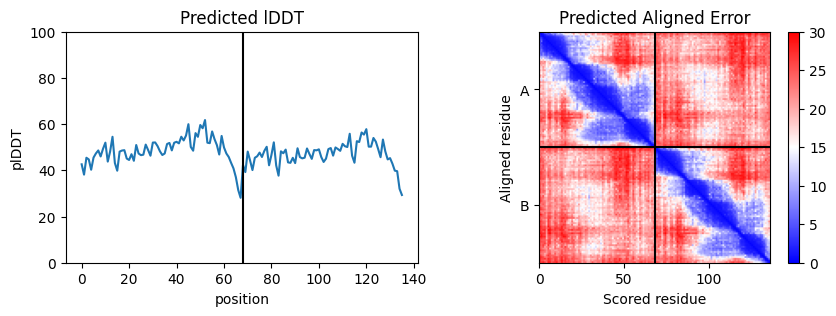

In [7]:
#@title Display 3D structure {run: "auto"}
#@markdown #### select which sequence to show (if more than one designed example)
# Index of the designed sequence to display
seq_num: int = 7 #@param ["0","1","2","3","4","5","6","7"] {type:"raw"}
# Guard against an out-of-range sequence index
assert seq_num < len(outs), f"ERROR: seq_num ({seq_num}) exceeds number of designed sequences ({num_sequences})"
# Index of the AlphaFold model whose prediction is displayed
model_num: int = 0 #@param ["0","1","2","3","4"] {type:"raw"}
# Guard against an out-of-range model index
assert model_num < len(outs[0]), f"ERROR: model_num ({num_models}) exceeds number of model params used ({num_models})"
#@markdown #### options

# Coloring mode for the viewer: chain, confidence (pLDDT), or rainbow
color: str = "rainbow" #@param ["chain", "confidence", "rainbow"]
# The viewer expects the literal name "lDDT" for the confidence coloring
if color == "confidence": color = "lDDT"
# Whether side-chain atoms are drawn
show_sidechains: bool = False #@param {type:"boolean"}
# Whether only the main chain is drawn
show_mainchains: bool = False #@param {type:"boolean"}

# Interactive 3D view of the saved prediction; Js=LS[seq_num] keeps chain numbering
v: Any = cf.show_pdb(f"out_seq_{seq_num}_model_{model_num}.pdb", show_sidechains, show_mainchains, color,
                color_HP=True, size=(800,480), Ls=LS[seq_num])
# Hover labels show residue name and index; the label is removed on mouse-out
v.setHoverable({}, True,
               '''function(atom,viewer,event,container){if(!atom.label){atom.label=viewer.addLabel("      "+atom.resn+":"+atom.resi,{position:atom,backgroundColor:'mintcream',fontColor:'black'});}}''',
               '''function(atom,viewer){if(atom.label){viewer.removeLabel(atom.label);delete atom.label;}}''')
# Render the viewer in the notebook
v.show()
# Add the pLDDT color legend when confidence coloring is selected
if color == "lDDT":
  cf.plot_plddt_legend().show()

# Per-residue pLDDT (scaled to 0-100) and the PAE matrix for this prediction
cf.plot_confidence(plddts[seq_num][model_num]*100, paes[seq_num][model_num], Ls=LS[seq_num]).show()